# Olist E-Commerce Analysis: Growth, Delivery & Customer Retention

**Author:** Muhammad Zul Rezky Zaaki · **Tools:** SQL (DuckDB), Python (pandas, matplotlib)

Olist is a Brazilian marketplace that connects small sellers to large online stores. This notebook analyses **96,203 delivered orders** (Jan 2017 – Aug 2018) from Olist's public dataset to answer seven business questions:

1. How fast is the business growing, and when are the peaks?
2. Which product categories drive revenue?
3. Do late deliveries hurt customer satisfaction?
4. Which regions are hardest to serve?
5. Do customers come back?
6. Which customer segments should marketing target (RFM)?
7. How do customers pay?

Every number is computed with the SQL files in [`../sql`](../sql), so the logic can be reviewed query by query.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

con = duckdb.connect()
con.execute(f"SET file_search_path = '{ROOT.as_posix()}'")
con.execute((ROOT / "sql/00_setup.sql").read_text())

def q(name):
    """Run one of the SQL files in /sql and return a DataFrame."""
    return con.execute((ROOT / "sql" / name).read_text()).df()

# Chart style: one accent colour, quiet axes and grid
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#c3c2b7", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRAY, "axes.labelcolor": "#52514e", "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG / name, bbox_inches="tight")

## Data scope

The raw data has 9 tables (orders, customers, items, payments, reviews, products, sellers, categories, geolocation). `00_setup.sql` joins them into one **order-level table** and applies these rules:

- Only **delivered** orders (96% of all orders), because cancelled or in-transit orders have no delivery date or review.
- Only **complete months**: Jan 2017 – Aug 2018. The first and last months of the raw data have only a handful of orders.
- Customers are identified by `customer_unique_id`, because `customer_id` changes with every order.
- `order_value` = product price + freight, in Brazilian Real (BRL).

In [2]:
kpi = q("01_kpis.sql")
kpi.T.rename(columns={0: "value"})

,value
orders,96203.00
customers,93096.00
revenue_brl,15376431.00
avg_order_value_brl,159.83
avg_review_score,4.16
late_delivery_pct,6.80
median_delivery_days,10.00


## 1. How fast is the business growing?

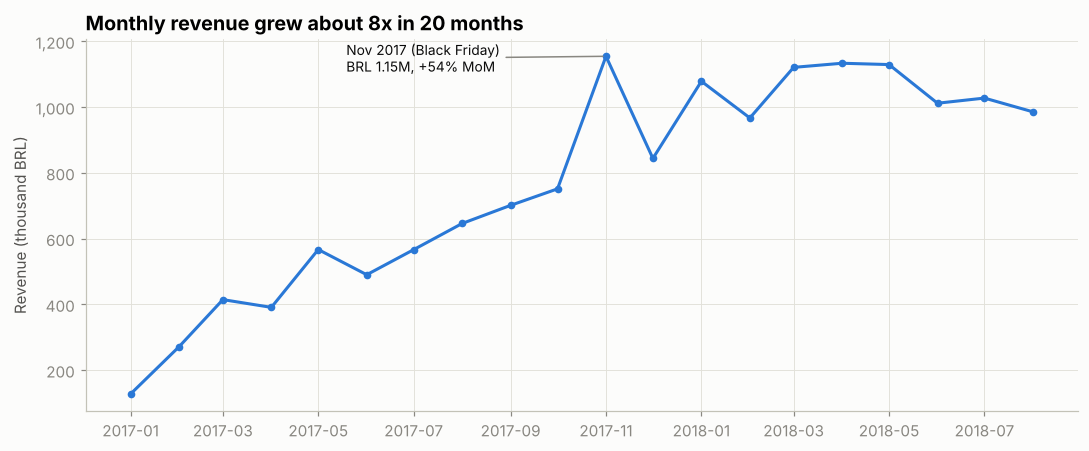

Jan 2017: 750 orders, BRL 127,482
Aug 2018: 6,351 orders, BRL 985,558
Average monthly revenue in 2018: BRL 1,056,634


In [3]:
trend = q("02_monthly_trend.sql")
trend["order_month"] = pd.to_datetime(trend["order_month"])

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(trend["order_month"], trend["revenue_brl"] / 1e3, color=BLUE, lw=2, marker="o", ms=4)
peak = trend.loc[trend["revenue_brl"].idxmax()]
ax.annotate(f"Nov 2017 (Black Friday)\nBRL {peak.revenue_brl/1e6:.2f}M, +{peak.revenue_mom_pct:.0f}% MoM",
            xy=(peak.order_month, peak.revenue_brl / 1e3), xytext=(-170, -10), textcoords="offset points",
            fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_title("Monthly revenue grew about 8x in 20 months")
ax.set_ylabel("Revenue (thousand BRL)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
save(fig, "01_monthly_revenue.png")
plt.show()

first, last = trend.iloc[0], trend.iloc[-1]
print(f"Jan 2017: {first.orders:,} orders, BRL {first.revenue_brl:,.0f}")
print(f"Aug 2018: {last.orders:,} orders, BRL {last.revenue_brl:,.0f}")
h1 = trend[(trend.order_month >= "2018-01-01")]
print(f"Average monthly revenue in 2018: BRL {h1.revenue_brl.mean():,.0f}")

**Insight.** Revenue rose from about BRL 127K in Jan 2017 to over BRL 1M per month in 2018. The single biggest month was **November 2017 (Black Friday)**, +54% over October. Growth then **flattened through 2018** at roughly BRL 0.97–1.13M per month, which means new growth has to come from somewhere other than simply acquiring more first-time buyers (see Section 5).

## 2. Which product categories drive revenue?

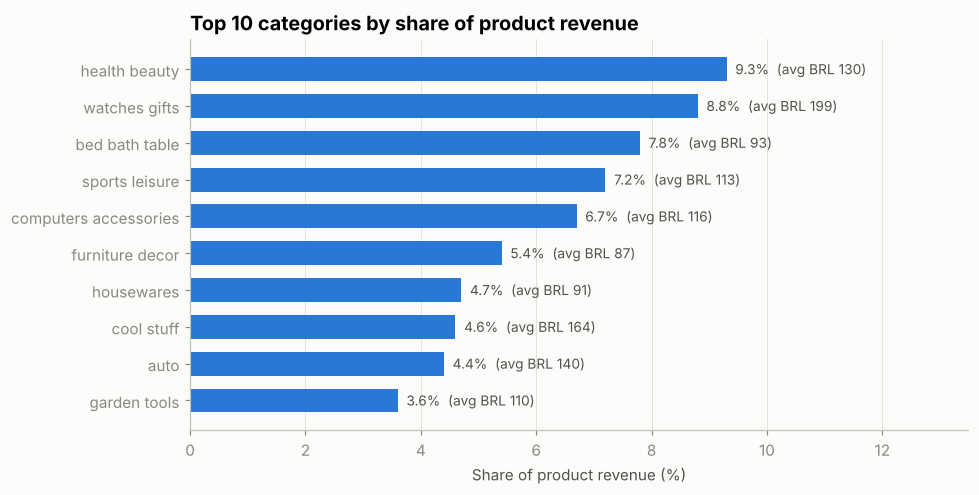

Top 10 categories = 62.5% of product revenue out of 74 categories


In [4]:
cats = q("03_top_categories.sql")
top = cats.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(top["category"].str.replace("_", " "), top["revenue_share_pct"], color=BLUE, height=0.65)
for y, (v, p) in enumerate(zip(top["revenue_share_pct"], top["avg_price_brl"])):
    ax.text(v + 0.15, y, f"{v:.1f}%  (avg BRL {p:.0f})", va="center", fontsize=9, color="#52514e")
ax.set_title("Top 10 categories by share of product revenue")
ax.set_xlabel("Share of product revenue (%)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top["revenue_share_pct"].max() * 1.45)
save(fig, "02_top_categories.png")
plt.show()

print(f"Top 10 categories = {cats.head(10).revenue_share_pct.sum():.1f}% of product revenue "
      f"out of {len(cats)} categories")

**Insight.** Revenue is concentrated: the **top 10 of 74 categories bring about 62% of product revenue**. *Health & beauty* leads, while *watches & gifts* earns almost as much with fewer items because of its higher average price (BRL 199). Promotions on these categories have the largest effect on total revenue.

## 3. Do late deliveries hurt customer satisfaction?

,delivery,orders,avg_review,pct_bad_reviews_1_2,pct_5_star
0,On time,89182,4.29,9.2,62.3
1,Late,6378,2.27,62.4,16.5


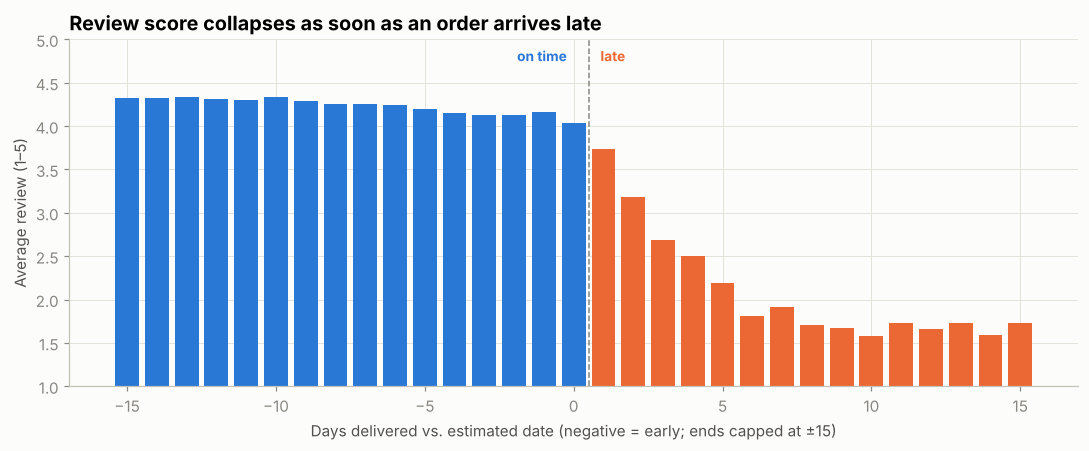

In [5]:
dvr = q("04_delivery_vs_review.sql")
display(dvr)

by_delay = con.execute("""
    SELECT LEAST(GREATEST(DATE_DIFF('day', estimated_at::DATE, delivered_at::DATE), -15), 15) AS days_vs_estimate,
           COUNT(*) AS orders, AVG(review_score) AS avg_review
    FROM orders WHERE review_score IS NOT NULL
    GROUP BY 1 ORDER BY 1
""").df()

fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [ORANGE if d > 0 else BLUE for d in by_delay["days_vs_estimate"]]
ax.bar(by_delay["days_vs_estimate"], by_delay["avg_review"], color=colors, width=0.8)
ax.axvline(0.5, color=MUTED, lw=1, ls="--")
ax.text(0.9, 4.75, "late", color=ORANGE, fontsize=9, fontweight="bold")
ax.text(-1.9, 4.75, "on time", color=BLUE, fontsize=9, fontweight="bold")
ax.set_ylim(1, 5)
ax.set_title("Review score collapses as soon as an order arrives late")
ax.set_xlabel("Days delivered vs. estimated date (negative = early; ends capped at ±15)")
ax.set_ylabel("Average review (1–5)")
save(fig, "03_delivery_vs_review.png")
plt.show()

**Insight.** This is the strongest finding of the analysis. On-time orders average **4.29 stars**; late orders average **2.27**. **62% of late orders get a 1–2 star review**, compared with 9% of on-time orders. The drop happens on the *first* day past the estimate, so the promised date matters as much as the actual speed.

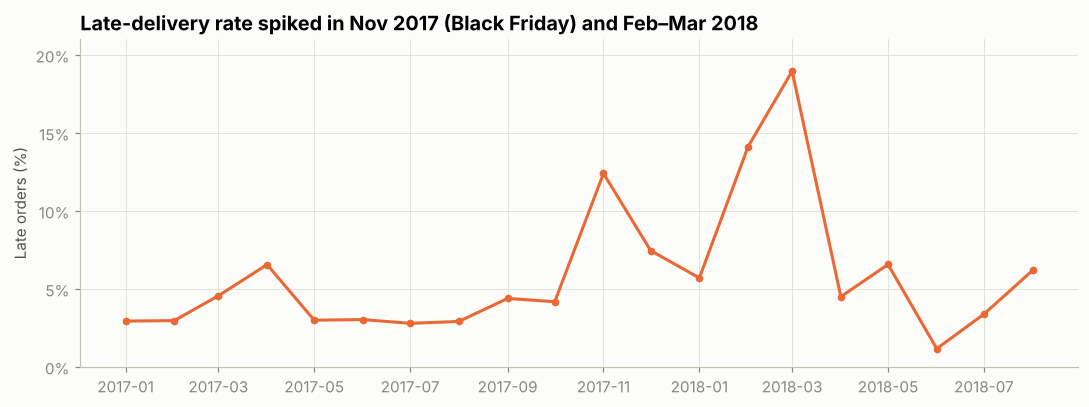

,order_month,late_pct,avg_review
10,2017-11-01,12.40,3.99
13,2018-02-01,14.13,3.88
14,2018-03-01,18.96,3.81


In [6]:
late = con.execute("""
    SELECT order_month, 100 * AVG(is_late::INT) AS late_pct, AVG(review_score) AS avg_review
    FROM orders GROUP BY 1 ORDER BY 1
""").df()
late["order_month"] = pd.to_datetime(late["order_month"])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(late["order_month"], late["late_pct"], color=ORANGE, lw=2, marker="o", ms=4)
ax.set_title("Late-delivery rate spiked in Nov 2017 (Black Friday) and Feb–Mar 2018")
ax.set_ylabel("Late orders (%)")
ax.set_ylim(0, 21)
ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
save(fig, "04_late_rate_by_month.png")
plt.show()
display(late[late.late_pct > 10].round({"late_pct": 2, "avg_review": 2}))

**Insight.** The late rate usually stays below 7%, but it jumped to **12% in Nov 2017** and **14–19% in Feb–Mar 2018**, and the average review fell to 3.8 in those months. Logistics capacity did not keep up with demand peaks, so peak-season planning is a concrete lever for satisfaction.

## 4. Which regions are hardest to serve?

,orders,median_delivery_days,late_pct,avg_review,order_share_pct,freight_pct_of_product
region,,,,,,
Southeast,66020,9.0,6.13,4.18,68.63,15.22
South,13767,12.0,5.92,4.19,14.31,17.71
Center-West,5610,13.0,6.54,4.13,5.83,17.68
Northeast,9015,17.0,12.76,3.97,9.37,21.79
North,1791,20.0,8.60,4.03,1.86,22.72


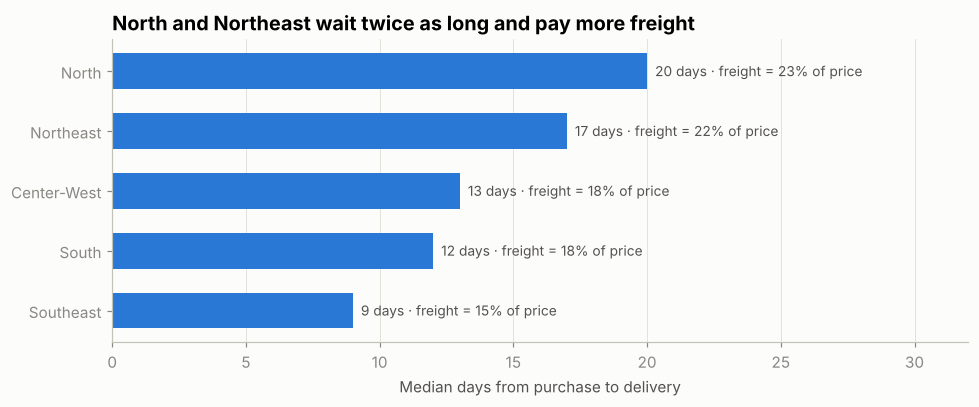

In [7]:
states = q("05_states.sql")
REGION = {**dict.fromkeys(["AC","AP","AM","PA","RO","RR","TO"], "North"),
          **dict.fromkeys(["AL","BA","CE","MA","PB","PE","PI","RN","SE"], "Northeast"),
          **dict.fromkeys(["DF","GO","MT","MS"], "Center-West"),
          **dict.fromkeys(["ES","MG","RJ","SP"], "Southeast"),
          **dict.fromkeys(["PR","RS","SC"], "South")}
orders_r = con.execute("SELECT customer_state, delivery_days, is_late, freight_value, product_value, review_score FROM orders").df()
orders_r["region"] = orders_r["customer_state"].map(REGION)
region = (orders_r.groupby("region")
          .agg(orders=("is_late", "size"), median_delivery_days=("delivery_days", "median"),
               late_pct=("is_late", "mean"), freight=("freight_value", "sum"),
               product=("product_value", "sum"), avg_review=("review_score", "mean"))
          .assign(order_share_pct=lambda d: 100 * d.orders / d.orders.sum(),
                  late_pct=lambda d: 100 * d.late_pct,
                  freight_pct_of_product=lambda d: 100 * d.freight / d["product"])
          .drop(columns=["freight", "product"])
          .sort_values("median_delivery_days"))
display(region.round(2))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(region.index, region["median_delivery_days"], color=BLUE, height=0.6)
for y, (d, f) in enumerate(zip(region["median_delivery_days"], region["freight_pct_of_product"])):
    ax.text(d + 0.3, y, f"{d:.0f} days · freight = {f:.0f}% of price", va="center", fontsize=9, color="#52514e")
ax.set_title("North and Northeast wait twice as long and pay more freight")
ax.set_xlabel("Median days from purchase to delivery")
ax.set_xlim(0, region["median_delivery_days"].max() * 1.6)
ax.grid(axis="y", visible=False)
save(fig, "05_region_delivery.png")
plt.show()

**Insight.** São Paulo alone is **42% of orders**, and the Southeast region is 69%. Customers in the **North and Northeast** wait a median **17–20 days** (vs 9 in the Southeast), pay freight equal to **~22% of the product price** (vs 15%), and leave lower reviews. Most sellers are in the Southeast, so distance drives both cost and delay.

## 5. Do customers come back?

,customers,repeat_customers,repeat_rate_pct,repeat_revenue_share_pct
0,93096,2789.0,3.0,5.6


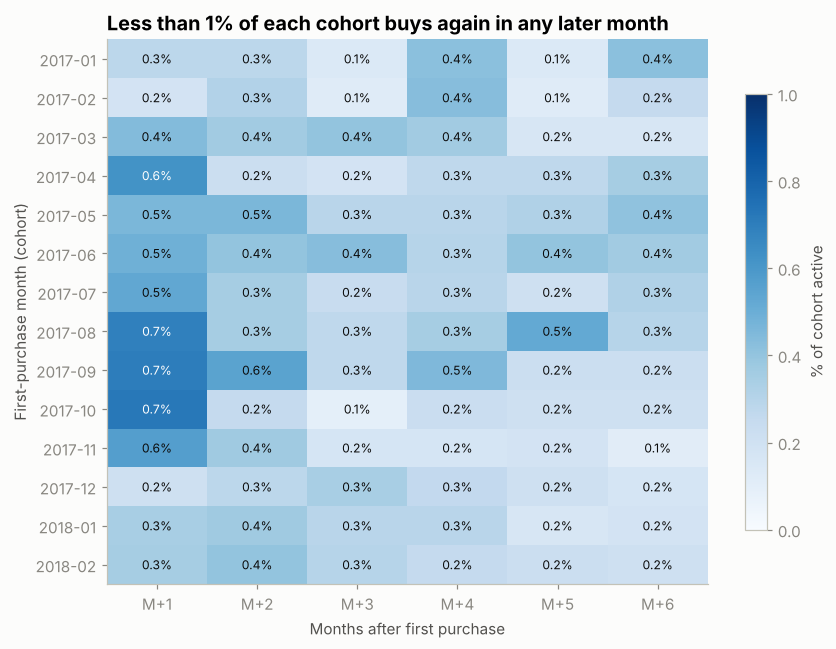

In [8]:
rep = q("06_repeat_customers.sql")
display(rep)

coh = q("07_cohort_retention.sql")
coh["cohort_month"] = pd.to_datetime(coh["cohort_month"]).dt.strftime("%Y-%m")
pivot = (coh[(coh.months_since_first.between(1, 6))]
         .pivot(index="cohort_month", columns="months_since_first", values="retention_pct")
         .loc[lambda d: d.index <= "2018-02"])

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(pivot.shape[1]), [f"M+{c}" for c in pivot.columns])
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else INK)
ax.grid(False)
ax.set_title("Less than 1% of each cohort buys again in any later month")
ax.set_xlabel("Months after first purchase")
ax.set_ylabel("First-purchase month (cohort)")
fig.colorbar(im, ax=ax, label="% of cohort active", shrink=0.8)
save(fig, "06_cohort_retention.png")
plt.show()

**Insight.** Only **3.0% of customers ever place a second order**, and they bring just 5.6% of revenue. In every monthly cohort, less than 1% of customers buy again in any later month. Olist depends almost entirely on new customers, which explains why growth flattened in 2018. Even small gains in repeat purchases would add revenue at a much lower cost than new acquisition.

## 6. RFM segmentation: who should marketing target?

Each customer is scored on **Recency** (days since last order) and **Monetary** value (total spend), from 1 to 5 using quintiles. **Frequency** is used directly (1 order vs 2+), because 97% of customers bought only once, so frequency quintiles would be meaningless.

,customers,revenue,median_recency_days,avg_spend,customer_pct,revenue_pct
segment,,,,,,
New high-value,14375,4343080.5,93.0,302.1,15.4,28.2
At risk (high value),13739,4224048.7,379.0,307.4,14.8,27.5
Needs attention,18015,2732363.4,219.0,151.7,19.4,17.8
Lost / hibernating,22509,1636081.1,383.0,72.7,24.2,10.6
New customers,21669,1579556.9,92.0,72.9,23.3,10.3
Loyal (lapsing),1595,475658.5,293.0,298.2,1.7,3.1
Champions,1194,385641.8,88.0,323.0,1.3,2.5


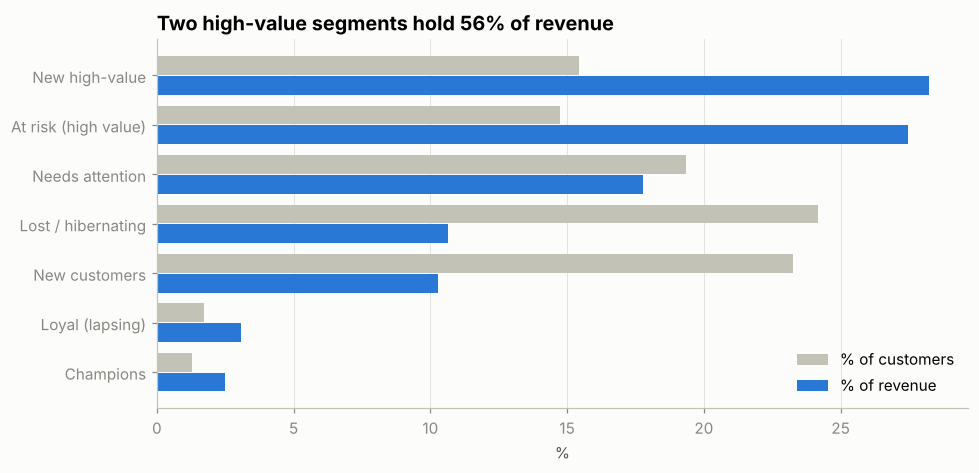

In [9]:
rfm = q("08_rfm.sql")
seg = (rfm.groupby("segment")
       .agg(customers=("customer_unique_id", "count"), revenue=("monetary", "sum"),
            median_recency_days=("recency_days", "median"), avg_spend=("monetary", "mean"))
       .assign(customer_pct=lambda d: 100 * d.customers / d.customers.sum(),
               revenue_pct=lambda d: 100 * d.revenue / d.revenue.sum())
       .sort_values("revenue_pct", ascending=False))
display(seg.round(1))

order = seg.index[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
y = range(len(order))
ax.barh([i + 0.2 for i in y], seg.loc[order, "customer_pct"], height=0.38, color=GRAY, label="% of customers")
ax.barh([i - 0.2 for i in y], seg.loc[order, "revenue_pct"], height=0.38, color=BLUE, label="% of revenue")
ax.set_yticks(list(y), order)
ax.set_xlabel("%")
ax.set_title("Two high-value segments hold 56% of revenue")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "07_rfm_segments.png")
plt.show()

**Insight.** *New high-value* (recent, big spenders) and *At risk (high value)* (big spenders who have not bought in about a year) are each ~15% of customers but together hold **~56% of revenue**. Suggested actions:

- **New high-value:** a second-purchase offer within 30–60 days, before they go quiet.
- **At risk (high value):** a win-back campaign; they already proved they spend.
- **Champions / Loyal:** only ~3% of customers; a loyalty or referral programme to grow this group.

## 7. How do customers pay?

In [10]:
pay = q("09_payments.sql")
pay

,payment_type,orders,value_share_pct,avg_installments
0,credit_card,74088,78.5,3.5
1,boleto,19140,18.0,NaN
2,voucher,3670,2.2,NaN
3,debit_card,1482,1.4,NaN


**Insight.** **Credit card covers 78.5% of payment value**, with an average of **3.5 instalments**. *Boleto* (bank slip, similar to a bank transfer) is 18%. Instalment options are therefore part of the purchase decision and should stay prominent at checkout and in promotions.

## Summary & recommendations

| # | Finding | Recommendation |
|---|---|---|
| 1 | Late orders average **2.3 vs 4.3 stars**; 62% of them get 1–2 stars. | Set more conservative delivery estimates and alert customers early when an order will be late. |
| 2 | Late rate jumped to **12–19%** around Black Friday and Feb–Mar 2018. | Plan carrier capacity and seller cut-off times ahead of peak seasons. |
| 3 | Only **3% of customers** buy again; cohort retention stays below 1%. | Start retention work: post-purchase emails, second-order vouchers, loyalty points. |
| 4 | Two high-value RFM segments hold **~56% of revenue**. | Target *New high-value* with a second-order offer and *At risk* with win-back campaigns. |
| 5 | North/Northeast wait **17–20 days** and pay **~22%** freight. | Recruit sellers or use fulfilment hubs closer to these regions; test freight subsidies. |
| 6 | Top 10 categories = **~62%** of product revenue. | Focus campaigns on these categories, led by health & beauty and watches & gifts. |

**Limitations.** The data is a public sample of Olist's orders, with no marketing or cost data, so the findings show correlation, not causation (for example, late orders may also be larger or more remote). Revenue excludes cancelled orders.